# Pump and dump com LightGBM

Este notebook executa o detector de mercado do OONCA com quatro eventos históricos na Binance. Ele mostra como converter negócios individuais em janelas rotuladas, ajustar o LightGBM e avaliar alertas em um período posterior. O modelo detecta sinais no fechamento da janela. A análise é retrospectiva.

O piloto usa dois eventos no treino e dois no teste. Esse recorte ajuda a inspecionar o comportamento do agente e é pequeno demais para medir seu desempenho operacional. [Artigo de referência](https://doi.org/10.1109/ICCCN49398.2020.9209660) · [Eventos documentados](https://github.com/SystemsLab-Sapienza/pump-and-dump-dataset/blob/master/pump_telegram.csv) · [Negócios agregados da Binance](https://github.com/binance/binance-public-data#spot)

### Como executar

Na raiz do repositório, instale as dependências do projeto e os pacotes do notebook.

```bash
python -m pip install -r requirements.txt
python -m pip install jupyterlab matplotlib
jupyter lab ml_models/pump_dump_lightgbm.ipynb
```

O modo `pilot` baixa quatro arquivos públicos da Binance na primeira execução e os reutiliza nas seguintes. Para usar seus dados, selecione `local`, coloque os dois CSVs em `data/pump_dump/` e ajuste a data de corte. [Formato dos CSVs](../docs/pump-dump-agent.md)

In [1]:
from pathlib import Path
from urllib.request import urlopen
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter, PercentFormatter
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_recall_curve

cwd = Path.cwd().resolve()
root = next(
    (folder for folder in (cwd, *cwd.parents) if (folder / "app/models/pump_dump.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Abra este notebook a partir do repositório do OONCA.")
sys.path.insert(0, str(root))

from app.agent.pump_dump import build_pump_agent
from app.features.pump_dump import FEATURES, WINDOW_MINUTES, build_features, label_features
from app.ingestion.pump_dump import MARKET, read_events, read_trades
from app.models.pump_dump import ALERT, train

DATA_MODE = "pilot"  # "local" usa os seus CSVs
DATA_DIR = root / "data/pump_dump"
CHUNK_SECONDS = 25
TEST_FROM = pd.Timestamp("2018-09-15T00:00:00Z")
THRESHOLD = 0.5

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#dde5ee",
    "grid.alpha": 0.75,
    "font.size": 10,
})
TEAL, BLUE, ORANGE = "#087f7d", "#2457a6", "#bd4e20"

## 1. Preparar os dados

Cada linha de `trades.csv` representa um negócio agregado, com preço, quantidade, horário e lado agressor. Na Binance, `isBuyerMaker=True` indica que o agressor vendeu. Cada linha de `events.csv` registra um sinal documentado para um par e uma exchange.

Os horários públicos do piloto têm precisão de minuto. Quando houver registros originais com segundos, prefira esses timestamps para localizar melhor a janela de início.

In [2]:
PILOT_EVENTS = [
    ("VIBE", "2018-07-14", "17:00"),
    ("VIBE", "2018-09-09", "19:00"),
    ("NAV", "2018-09-22", "19:00"),
    ("EVX", "2018-10-06", "19:00"),
]


def prepare_pilot(directory):
    directory.mkdir(parents=True, exist_ok=True)
    frames = []
    event_records = []
    for asset, day, hour in PILOT_EVENTS:
        pair = f"{asset}BTC"
        symbol = f"{asset}/BTC"
        archive = directory / f"{pair}-aggTrades-{day}.zip"
        if not archive.is_file():
            url = f"https://data.binance.vision/data/spot/daily/aggTrades/{pair}/{archive.name}"
            with urlopen(url, timeout=30) as response:
                archive.write_bytes(response.read())

        raw = pd.read_csv(archive, header=None, usecols=[0, 1, 2, 5, 6], dtype=str)
        raw.columns = ["trade_id", "price", "quantity", "timestamp", "buyer_is_maker"]
        side = raw.pop("buyer_is_maker").str.lower().map({"true": "sell", "false": "buy"})
        frames.append(raw.assign(exchange="binance", symbol=symbol, side=side, segment=day))
        event_records.append(("binance", symbol, f"{day}T{hour}:00Z"))

    trades_path, events_path = directory / "trades.csv", directory / "events.csv"
    pd.concat(frames, ignore_index=True).to_csv(trades_path, index=False)
    pd.DataFrame(event_records, columns=[*MARKET, "timestamp"]).to_csv(events_path, index=False)
    return trades_path, events_path


if DATA_MODE == "pilot":
    trades_path, events_path = prepare_pilot(DATA_DIR / "pilot")
elif DATA_MODE == "local":
    trades_path, events_path = DATA_DIR / "trades.csv", DATA_DIR / "events.csv"
else:
    raise ValueError("Selecione 'pilot' ou 'local' em DATA_MODE.")

trades = read_trades(trades_path)
events = read_events(events_path).sort_values("timestamp")
print(f"{len(trades):,} negócios em {trades[MARKET].drop_duplicates().shape[0]} mercados.")
display(events[[*MARKET, "timestamp"]].reset_index(drop=True))

57,491 negócios em 3 mercados.


,exchange,symbol,timestamp
0,binance,VIBE/BTC,2018-07-14 17:00:00+00:00
1,binance,VIBE/BTC,2018-09-09 19:00:00+00:00
2,binance,NAV/BTC,2018-09-22 19:00:00+00:00
3,binance,EVX/BTC,2018-10-06 19:00:00+00:00


## 2. Construir as features e rotular as janelas

As janelas são intervalos UTC semiabertos de 25 segundos. O rótulo vale `1` quando o horário documentado cai na janela do mesmo mercado. O valor `0` significa ausência de um evento no catálogo fornecido.

O modelo usa nove features calculadas no fechamento, com sete horas de histórico. Uma *rush order* é aproximada por um milissegundo em que houve pelo menos dois negócios de compra agressora. O treino usa janelas encerradas até a data de corte. No teste, até o dado mais antigo usado por cada janela precisa ser posterior ou igual ao corte.

In [3]:
features = build_features(trades, CHUNK_SECONDS)
labeled = label_features(features, events, CHUNK_SECONDS)
train_rows = labeled.loc[labeled["chunk_end"].le(TEST_FROM)]
test_rows = labeled.loc[labeled["history_start"].ge(TEST_FROM)].reset_index(drop=True)

print(f"Janela de {CHUNK_SECONDS} s com {WINDOW_MINUTES[CHUNK_SECONDS]} min de histórico.")
summary = pd.DataFrame({
    "Período": ["Treino", "Teste"],
    "Janelas": [len(train_rows), len(test_rows)],
    "Eventos rotulados": [int(train_rows["label"].sum()), int(test_rows["label"].sum())],
})
display(summary)

Janela de 25 s com 420 min de histórico.


,Período,Janelas,Eventos rotulados
0,Treino,4888,2
1,Teste,4888,2


## 3. Treinar o LightGBM e avaliar o teste

O notebook chama a mesma função de treino usada pela CLI. Ela ajusta o LightGBM com pesos balanceados calculados a partir do treino e aplica a pausa de 30 minutos após um alerta por mercado. O score é usado para ordenar suspeitas e aplicar um limiar fixo. A escala do score não foi calibrada como probabilidade.

In [4]:
model, metrics = train(labeled, CHUNK_SECONDS, TEST_FROM, THRESHOLD)
scored = model.score(test_rows)
alerts = scored["status"].eq(ALERT)
positives = scored["label"].eq(1)

report = pd.Series({
    "Precisão": metrics["precision"],
    "Revocação": metrics["recall"],
    "F1": metrics["f1"],
    "Precisão média antes da pausa (AP)": metrics["average_precision_before_cooldown"],
}, name="Teste")
display(report)
print(f"Alertas no teste: {alerts.sum()} · Eventos detectados: {(alerts & positives).sum()}/{positives.sum()}")

event_scores = scored.loc[positives, [*MARKET, "chunk_start", "chunk_end", "score", "status"]].copy()
event_scores["score"] = event_scores["score"].map(lambda value: f"{value:.3g}")
display(event_scores.reset_index(drop=True))

Precisão                              0.000000
Revocação                             0.000000
F1                                    0.000000
Precisão média antes da pausa (AP)    0.001624
Name: Teste, dtype: float64

Alertas no teste: 0 · Eventos detectados: 0/2


,exchange,symbol,chunk_start,chunk_end,score,status
0,binance,NAV/BTC,2018-09-22 19:00:00+00:00,2018-09-22 19:00:25+00:00,9.67e-06,NO_ALERT
1,binance,EVX/BTC,2018-10-06 19:00:00+00:00,2018-10-06 19:00:25+00:00,7.92e-06,NO_ALERT


## 4. Inspecionar um evento do teste

O primeiro evento do teste é mostrado com o preço de fechamento de cada janela, o volume na moeda de cotação, a contagem de compras agrupadas no mesmo milissegundo e o score. A linha vertical indica o horário catalogado. Os pontos de mercado e de score são posicionados no fechamento das janelas.

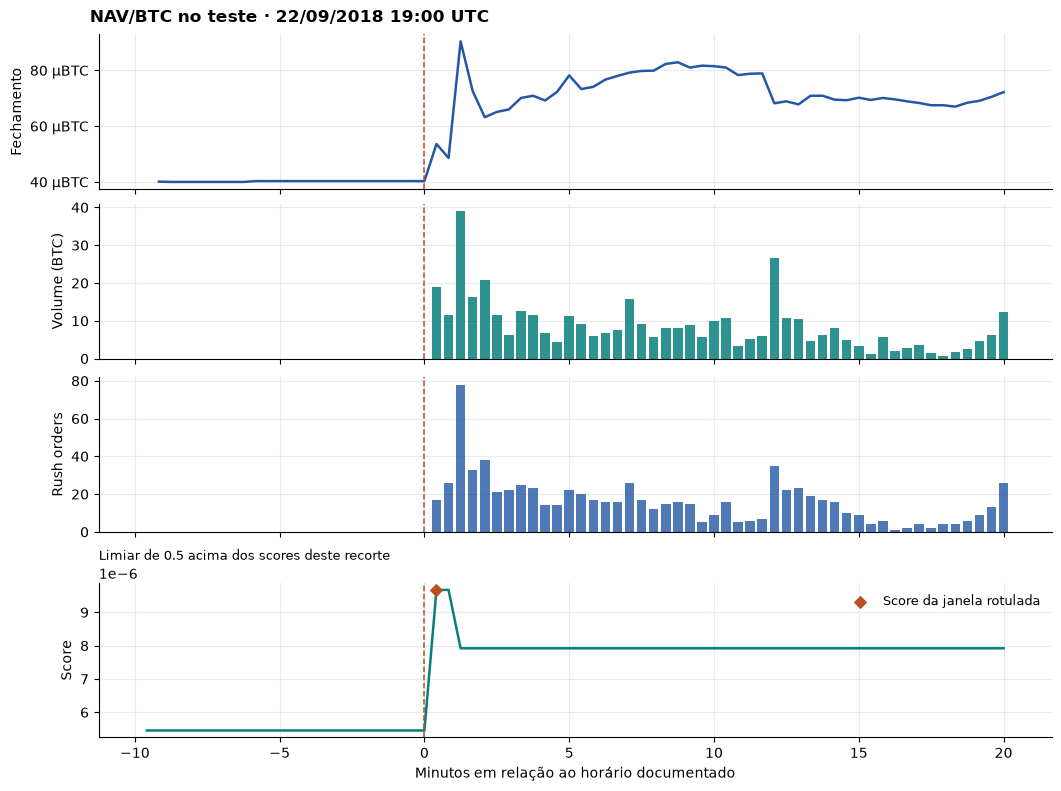

In [5]:
event = scored.loc[positives].iloc[0]
event_time = event["chunk_start"]
catalogued = events.loc[
    events["exchange"].eq(event["exchange"])
    & events["symbol"].eq(event["symbol"])
    & events["timestamp"].dt.floor(f"{CHUNK_SECONDS}s").eq(event_time),
    "timestamp",
].iloc[0]

lookback, lookahead = pd.Timedelta(minutes=10), pd.Timedelta(minutes=20)
left, right = event_time - lookback, event_time + lookahead
delta = pd.Timedelta(seconds=CHUNK_SECONDS)
same_market = trades["exchange"].eq(event["exchange"]) & trades["symbol"].eq(event["symbol"])
trade_slice = trades.loc[
    same_market & trades["segment"].eq(event["segment"])
    & trades["timestamp"].ge(left) & trades["timestamp"].lt(right)
].sort_values("timestamp", kind="stable")

period = trade_slice["timestamp"].dt.floor(f"{CHUNK_SECONDS}s")
grid = pd.date_range(left, right, freq=delta, inclusive="left")
close = trade_slice.groupby(period)["price"].last().reindex(grid)
volume = (trade_slice["price"] * trade_slice["quantity"]).groupby(period).sum().reindex(grid, fill_value=0)
buy_times = trade_slice.loc[trade_slice["side"].eq("buy"), "timestamp"].dt.floor("ms")
rush = buy_times.value_counts()
rush_by_bucket = rush[rush.gt(1)].index.floor(f"{CHUNK_SECONDS}s").value_counts().reindex(grid, fill_value=0)
minutes = (grid + delta - catalogued).total_seconds() / 60

same_test_market = scored["exchange"].eq(event["exchange"]) & scored["symbol"].eq(event["symbol"])
visible = scored.loc[
    same_test_market & scored["segment"].eq(event["segment"]) & scored["chunk_start"].between(left, right, inclusive="left")
]
score_minutes = (visible["chunk_end"] - catalogued).dt.total_seconds() / 60

fig, axes = plt.subplots(4, 1, figsize=(10.5, 7.8), sharex=True, layout="constrained")
fig.suptitle(f"{event['symbol']} no teste · {catalogued:%d/%m/%Y %H:%M} UTC", x=0.08, ha="left", weight="bold")
axes[0].plot(minutes, close.ffill(), color=BLUE, lw=1.8)
quote_currency = event["symbol"].partition("/")[2]
axes[0].set_ylabel("Fechamento")
axes[0].yaxis.set_major_formatter(EngFormatter(unit=quote_currency))
axes[1].bar(minutes, volume, width=0.33, color=TEAL, alpha=0.85)
axes[1].set_ylabel(f"Volume ({quote_currency})" if quote_currency else "Volume cotado")
axes[1].yaxis.set_major_formatter(EngFormatter())
axes[2].bar(minutes, rush_by_bucket, width=0.33, color=BLUE, alpha=0.8)
axes[2].set_ylabel("Rush orders")
axes[3].plot(score_minutes, visible["score"], color=TEAL, lw=1.8)
axes[3].scatter(
    (event["chunk_end"] - catalogued).total_seconds() / 60, event["score"],
    color=ORANGE, marker="D", s=34, zorder=4, label="Score da janela rotulada",
)
if visible["score"].max() < THRESHOLD:
    axes[3].set_title(f"Limiar de {THRESHOLD:g} acima dos scores deste recorte", loc="left", fontsize=9)
else:
    axes[3].axhline(THRESHOLD, color=TEAL, ls=":", label=f"Limiar de {THRESHOLD:g}")
axes[3].set_ylabel("Score")
axes[3].set_xlabel("Minutos em relação ao horário documentado")
axes[3].legend(loc="upper right", frameon=False, fontsize=9)
for ax in axes:
    ax.axvline(0, ls="--", lw=1.1, color=ORANGE)
plt.show()

## 5. Ver os erros e os sinais usados pelo modelo

A matriz usa os alertas emitidos após o limiar e a pausa entre alertas. A curva precisão–revocação usa os scores antes da pausa para mostrar como o modelo ordena as janelas. A linha pontilhada representa a proporção de positivos no teste. O ganho por feature resume quanto cada variável contribuiu para reduzir o erro de treino nas divisões das árvores.

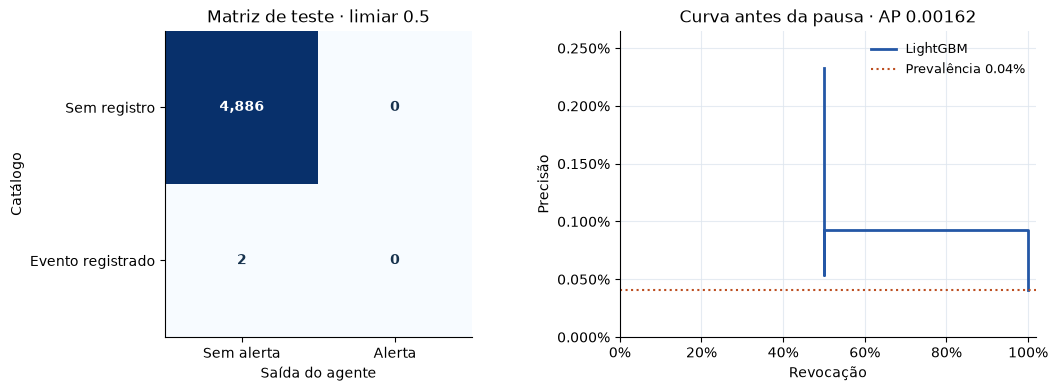

In [6]:
matrix = confusion_matrix(positives, alerts, labels=[False, True])
precision, recall, _ = precision_recall_curve(positives, scored["score"])
prevalence = positives.mean()

fig, (left_ax, right_ax) = plt.subplots(1, 2, figsize=(10.5, 3.8), layout="constrained")
left_ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(1, matrix.max()))
for row in range(2):
    for column in range(2):
        value = matrix[row, column]
        left_ax.text(
            column, row, f"{value:,}", ha="center", va="center", weight="bold",
            color="white" if value > matrix.max() * 0.5 else "#17324d",
        )
left_ax.set(
    xticks=[0, 1], xticklabels=["Sem alerta", "Alerta"],
    yticks=[0, 1], yticklabels=["Sem registro", "Evento registrado"],
    xlabel="Saída do agente", ylabel="Catálogo",
    title=f"Matriz de teste · limiar {THRESHOLD:g}",
)
left_ax.grid(False)

# The terminal point of the curve has no predicted positives.
right_ax.step(recall[:-1][::-1], precision[:-1][::-1], where="pre", lw=2, color=BLUE, label="LightGBM")
right_ax.axhline(prevalence, color=ORANGE, ls=":", label=f"Prevalência {prevalence:.2%}")
right_ax.set(
    xlim=(0, 1.02), ylim=(0, min(1.02, max(prevalence, precision[:-1].max()) * 1.14)),
    xlabel="Revocação", ylabel="Precisão",
    title=f"Curva antes da pausa · AP {metrics['average_precision_before_cooldown']:.3g}",
)
right_ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
right_ax.yaxis.set_major_formatter(PercentFormatter(1))
right_ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.show()

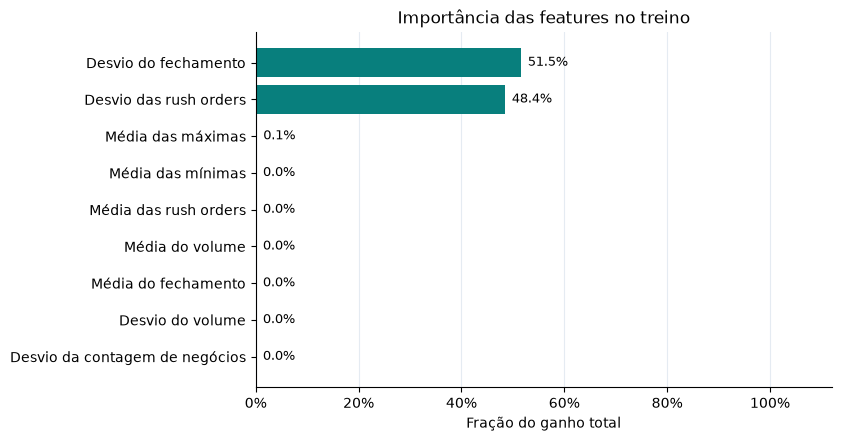

In [7]:
feature_names = [
    "Desvio das rush orders", "Média das rush orders", "Desvio da contagem de negócios",
    "Desvio do volume", "Média do volume", "Desvio do fechamento",
    "Média do fechamento", "Média das máximas", "Média das mínimas",
]
gain = pd.Series(model.classifier.booster_.feature_importance(importance_type="gain"), index=FEATURES)
gain.index = feature_names
share = (gain / gain.sum() if gain.sum() else gain).sort_values()

fig, ax = plt.subplots(figsize=(8.3, 4.3), layout="constrained")
ax.barh(share.index, share, color=TEAL)
ax.set(
    xlim=(0, 1.12), xticks=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    title="Importância das features no treino", xlabel="Fração do ganho total",
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", visible=False)
for index, value in enumerate(share):
    ax.text(value + 0.014, index, f"{value:.1%}", va="center", fontsize=9)
plt.show()

## 6. Rodar o agente LangGraph

O fluxo coleta evidências dos negócios, pontua as janelas e gera uma explicação local para cada alerta. Esta chamada reproduz o CSV inteiro e inclui as janelas de treino. A avaliação acima foi calculada somente com as janelas de teste.

In [8]:
agent = build_pump_agent(model)
replay = agent.invoke({"trades_path": str(trades_path)})["detections"]
display(replay["status"].value_counts().rename("Janelas no replay"))

replay_alerts = replay.loc[replay["status"].eq(ALERT), [*MARKET, "chunk_end", "score", "explanation"]]
if len(replay_alerts):
    display(replay_alerts.head(5).reset_index(drop=True))
else:
    print(f"Nenhuma janela do replay ultrapassou o limiar de {THRESHOLD:g}.")

status
NO_ALERT          9774
SUSPECTED_PUMP       2
Name: Janelas no replay, dtype: int64

,exchange,symbol,chunk_end,score,explanation
0,binance,VIBE/BTC,2018-07-14 17:00:25+00:00,0.999999,Padrão compatível com início de pump em binanc...
1,binance,VIBE/BTC,2018-09-09 19:00:25+00:00,0.999999,Padrão compatível com início de pump em binanc...


### Como interpretar o piloto

O recorte foi escolhido ao redor de sinais conhecidos. A proporção de positivos e o volume de alertas podem mudar em um feed contínuo. Um alerta indica um padrão compatível com pump. A confirmação exige evidência externa. Para avaliar o modelo com seus dados, use períodos mais longos com atividade regular e mais eventos documentados em dias distintos.